# Programming Assignment: Build a CNN for image recognition.

### Name: Qi Pan

## 0. You will do the following:

1. Read, complete, and run the code.

2. **Make substantial improvements** to maximize the accuracy.

3. Convert the .IPYNB file to .HTML file.

    * The HTML file must contain the code and the output after execution.

    * Missing **the output after execution** will not be graded.

4. Upload the .HTML file to your Google Drive, Dropbox, or Github repo. (If you submit the file to Google Drive or Dropbox, you must make the file "open-access". The delay caused by "deny of access" may result in late penalty.)

5. On Canvas, submit the Google Drive/Dropbox/Github link to the HTML file.


## Requirements:

1. You can use whatever CNN architecture, including VGG, Inception, and ResNet. However, you must build the networks layer by layer. You must NOT import the architectures from ```keras.applications```.

2. Make sure ```BatchNormalization``` is between a ```Conv```/```Dense``` layer and an ```activation``` layer.

3. If you want to regularize a ```Conv```/```Dense``` layer, you should place a ```Dropout``` layer **before** the ```Conv```/```Dense``` layer.

4. An accuracy above 70% is considered reasonable. An accuracy above 80% is considered good. Without data augmentation, achieving 80% accuracy is difficult.


## Google Colab

- If you do not have GPU, the training of a CNN can be slow. Google Colab is a good option (Runtime --> Change runtime type --> GPU).

- Keep in mind that the IPYNB and HTML files must contain the outputs. In Colab, do NOT check ```Omit code cell output when saving this notebook```.

## 1. Data preparation

### 1.1. Load data

CIFAR-10 is loaded from the Hugging Face mirror (```uoft-cs/cifar10```), which is much faster than the original Toronto server. If that fails, the code falls back to ```keras.datasets.cifar10```. Both give exactly the same data: 50K training and 10K test images of size 32x32x3, with labels in $\{0,\dots,9\}$.

In [1]:
import numpy

def load_cifar10_from_huggingface():
    from datasets import load_dataset
    ds = load_dataset('uoft-cs/cifar10')
    def to_numpy(split):
        x = numpy.stack([numpy.asarray(img) for img in split['img']]).astype('uint8')  # (N, 32, 32, 3)
        y = numpy.asarray(split['label'], dtype='uint8').reshape(-1, 1)                 # (N, 1)
        return x, y
    return to_numpy(ds['train']), to_numpy(ds['test'])

try:
    (x_train, y_train), (x_test, y_test) = load_cifar10_from_huggingface()
    print('Loaded CIFAR-10 from Hugging Face.')
except Exception as e:
    print('Hugging Face loading failed (' + str(e)[:100] + '), falling back to keras.datasets.cifar10 ...')
    from keras.datasets import cifar10
    (x_train, y_train), (x_test, y_test) = cifar10.load_data()

print('shape of x_train: ' + str(x_train.shape))
print('shape of y_train: ' + str(y_train.shape))
print('shape of x_test: ' + str(x_test.shape))
print('shape of y_test: ' + str(y_test.shape))
print('number of classes: ' + str(numpy.max(y_train) - numpy.min(y_train) + 1))

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Loaded CIFAR-10 from Hugging Face.
shape of x_train: (50000, 32, 32, 3)
shape of y_train: (50000, 1)
shape of x_test: (10000, 32, 32, 3)
shape of y_test: (10000, 1)
number of classes: 10


### 1.2. One-hot encode the labels

In the input, a label is a scalar in $\{0, 1, \cdots , 9\}$. One-hot encode transform such a scalar to a $10$-dim vector. E.g., a scalar ```y_train[j]=3``` is transformed to the vector ```y_train_vec[j]=[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]```.

1. Define a function ```to_one_hot``` that transforms an $n\times 1$ array to a $n\times 10$ matrix.

2. Apply the function to ```y_train``` and ```y_test```.

In [2]:
def to_one_hot(y, num_class=10):
    y = numpy.asarray(y).reshape(-1).astype(int)   # (n, 1) -> (n,)
    one_hot = numpy.zeros((y.shape[0], num_class), dtype='float32')
    one_hot[numpy.arange(y.shape[0]), y] = 1.0     # put a 1 at the column given by the label
    return one_hot

y_train_vec = to_one_hot(y_train)
y_test_vec = to_one_hot(y_test)

print('Shape of y_train_vec: ' + str(y_train_vec.shape))
print('Shape of y_test_vec: ' + str(y_test_vec.shape))

print(y_train[0])
print(y_train_vec[0])

Shape of y_train_vec: (50000, 10)
Shape of y_test_vec: (10000, 10)
[0]
[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


#### Remark: the outputs should be
* Shape of y_train_vec: (50000, 10)
* Shape of y_test_vec: (10000, 10)
* [6]
* [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]

### 1.3. Randomly partition the training set to training and validation sets

Randomly partition the 50K training samples to 2 sets:
* a training set containing 40K samples
* a validation set containing 10K samples

In [3]:
numpy.random.seed(0)   # make the split reproducible
rand_indices = numpy.random.permutation(50000)
train_indices = rand_indices[0:40000]
valid_indices = rand_indices[40000:50000]

x_val = x_train[valid_indices, :]
y_val = y_train_vec[valid_indices, :]

x_tr = x_train[train_indices, :]
y_tr = y_train_vec[train_indices, :]

print('Shape of x_tr: ' + str(x_tr.shape))
print('Shape of y_tr: ' + str(y_tr.shape))
print('Shape of x_val: ' + str(x_val.shape))
print('Shape of y_val: ' + str(y_val.shape))

Shape of x_tr: (40000, 32, 32, 3)
Shape of y_tr: (40000, 10)
Shape of x_val: (10000, 32, 32, 3)
Shape of y_val: (10000, 10)


### 1.4. Pre-processing: standardize the pixels

Pixels are integers in $[0, 255]$. We convert them to ```float32``` and standardize each color channel with the mean and std computed on the **40K training split only** (```x_tr```), so that neither the validation set nor the test set influences the pre-processing.

In [4]:
channel_mean = x_tr.reshape(-1, 3).mean(axis=0)
channel_std = x_tr.reshape(-1, 3).std(axis=0)
print('channel mean: ' + str(channel_mean))
print('channel std: ' + str(channel_std))

def standardize(x):
    return ((x.astype('float32') - channel_mean) / channel_std).astype('float32')

x_train_n = standardize(x_train)
x_test_n = standardize(x_test)
x_tr_n = standardize(x_tr)
x_val_n = standardize(x_val)

channel mean: [125.31637805 123.00030359 113.85058218]
channel std: [62.9701463  62.08780921 66.70614772]


## 2. Build a CNN and tune its hyper-parameters

1. Build a convolutional neural network model
2. Use the validation data to tune the hyper-parameters (e.g., network structure, and optimization algorithm)
    * Do NOT use test data for hyper-parameter tuning!!!
3. Try to achieve a validation accuracy as high as possible.

### 2.0. Setup: GPU check, mixed precision, output folder

* **Mixed precision** (float16 compute, float32 weights) roughly doubles the training speed on a T4/V100 GPU and does not change the accuracy. It is enabled only when a GPU is available. The final ```softmax``` is kept in float32 for numerical stability.
* **Output folder**: when running in Colab, Google Drive is mounted and the training curves, weights and final numbers are saved there, so nothing is lost if the Colab session disconnects.

In [5]:
import os, json, math
import keras
import tensorflow as tf
from keras import layers, models, regularizers

gpus = tf.config.list_physical_devices('GPU')
print('GPUs: ' + str(gpus))
if gpus:
    keras.mixed_precision.set_global_policy('mixed_float16')
print('Mixed-precision policy: ' + keras.mixed_precision.global_policy().name)

# where to save results
try:
    from google.colab import drive
    drive.mount('/content/drive')
    SAVE_DIR = '/content/drive/MyDrive/CS583_Programming2'
except Exception:
    SAVE_DIR = os.path.join(os.getcwd(), 'CS583_Programming2_outputs')
os.makedirs(SAVE_DIR, exist_ok=True)
print('Results will be saved to: ' + SAVE_DIR)

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed-precision policy: mixed_float16
Results will be saved to: /content/CS583_Programming2_outputs


### 2.1. The network

Improvements over the example network (a 2-conv-layer CNN):

* **VGG-style deeper network**: 3 stages $\times$ 2 conv layers (64 $\rightarrow$ 128 $\rightarrow$ 256 filters), each stage ends with max-pooling; then global average pooling and a small dense head.
* **Batch normalization**: every ```Conv```/```Dense``` layer (including the output layer) is followed by ```BatchNormalization``` and then the activation (```ReLU```, or ```softmax``` for the output layer). The Conv/Dense layers have no bias because BN already has a shift term.
* **Dropout**: placed *before* conv/dense layers (dropout rate grows with depth: 0.1, 0.2, 0.3 in the conv stages, 0.4 in the head). Also a small L2 weight decay.
* **Data augmentation**: random horizontal flip and random translation (up to 12.5%) are the first layers of the model. These layers are only active during training, so validation/test images are not modified.
* **Better optimization**: Adam with a warm-up + cosine learning-rate decay (instead of RMSprop with a tiny constant learning rate), label smoothing (0.1), and more epochs.

In [6]:
keras.utils.set_random_seed(0)

def conv_bn_relu(model, filters, l2):
    # Conv (no bias) -> BatchNorm -> ReLU
    model.add(layers.Conv2D(filters, (3, 3), padding='same', use_bias=False,
                            kernel_regularizer=regularizers.l2(l2)))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))

def build_cnn(filters=(64, 128, 256), drop=(0.1, 0.2, 0.3), head_drop=0.4, l2=1e-4):
    model = models.Sequential()
    model.add(keras.Input(shape=(32, 32, 3)))

    # data augmentation (active only in training)
    model.add(layers.RandomFlip('horizontal'))
    model.add(layers.RandomTranslation(0.125, 0.125, fill_mode='reflect'))

    for f, d in zip(filters, drop):
        conv_bn_relu(model, f, l2)
        model.add(layers.Dropout(d))          # Dropout BEFORE the next conv layer
        conv_bn_relu(model, f, l2)
        model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dropout(head_drop))      # Dropout BEFORE the dense layer
    model.add(layers.Dense(256, use_bias=False, kernel_regularizer=regularizers.l2(l2)))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.Dropout(head_drop))      # Dropout BEFORE the output layer
    model.add(layers.Dense(10, use_bias=False))   # Dense -> BN -> softmax
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('softmax', dtype='float32'))   # float32 output under mixed precision
    return model

model = build_cnn()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 256)      │             

 Total params: 1,217,256 (4.64 MB)

 Trainable params: 1,214,932 (4.63 MB)

 Non-trainable params: 2,324 (9.08 KB)

### 2.2. Training utilities: optimizer and learning-rate schedule

In [7]:
BATCH_SIZE = 128

def make_lr_callback(peak_lr, total_epochs, warmup_epochs=2, min_lr=1e-5):
    # linear warm-up, then cosine decay down to min_lr
    def schedule(epoch):
        if epoch < warmup_epochs:
            return peak_lr * (epoch + 1) / warmup_epochs
        progress = (epoch - warmup_epochs) / max(1, total_epochs - warmup_epochs)
        return min_lr + 0.5 * (peak_lr - min_lr) * (1 + math.cos(math.pi * progress))
    return keras.callbacks.LearningRateScheduler(schedule)

LABEL_SMOOTHING = 0.1   # soft targets: 0.9 for the true class, 0.1/9 for the others

def compile_model(model, learning_rate):
    model.compile(loss=keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING),
                  optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  metrics=['accuracy'])

### 2.3. Hyper-parameter tuning on the validation set

We compare 3 peak learning rates with a short (5-epoch) schedule and keep the one with the highest **validation** accuracy. To make the comparison less sensitive to the noise of a single epoch, the score of each candidate is the **mean validation accuracy over the last 3 epochs**. (The test set is not touched.)

In [8]:
TUNE_EPOCHS = 5
lr_candidates = [5e-4, 1e-3, 2e-3]
tune_results = {}

for lr in lr_candidates:
    print('===== peak learning rate = ' + str(lr) + ' =====')
    keras.backend.clear_session()      # free the memory of the previous model
    keras.utils.set_random_seed(0)
    m = build_cnn()
    compile_model(m, lr)
    h = m.fit(x_tr_n, y_tr, batch_size=BATCH_SIZE, epochs=TUNE_EPOCHS,
              validation_data=(x_val_n, y_val),
              callbacks=[make_lr_callback(lr, TUNE_EPOCHS, warmup_epochs=1)],
              verbose=2)
    tune_results[lr] = float(numpy.mean(h.history['val_accuracy'][-3:]))
    del m, h

print()
for lr, v in tune_results.items():
    print('peak lr = %g  ->  mean validation accuracy of the last 3 epochs = %.4f' % (lr, v))

best_lr = max(tune_results, key=tune_results.get)
print('Best peak learning rate: ' + str(best_lr))

===== peak learning rate = 0.0005 =====
Epoch 1/5
313/313 - 30s - 96ms/step - accuracy: 0.3791 - loss: 1.9200 - val_accuracy: 0.3157 - val_loss: 2.1266 - learning_rate: 5.0000e-04
Epoch 2/5
313/313 - 18s - 56ms/step - accuracy: 0.5474 - loss: 1.6133 - val_accuracy: 0.5628 - val_loss: 1.5522 - learning_rate: 5.0000e-04
Epoch 3/5
313/313 - 18s - 57ms/step - accuracy: 0.6169 - loss: 1.4684 - val_accuracy: 0.6153 - val_loss: 1.4822 - learning_rate: 4.2824e-04
Epoch 4/5
313/313 - 18s - 58ms/step - accuracy: 0.6724 - loss: 1.3588 - val_accuracy: 0.6475 - val_loss: 1.3540 - learning_rate: 2.5500e-04
Epoch 5/5
313/313 - 18s - 58ms/step - accuracy: 0.7092 - loss: 1.2835 - val_accuracy: 0.7366 - val_loss: 1.1944 - learning_rate: 8.1759e-05
===== peak learning rate = 0.001 =====
Epoch 1/5
313/313 - 23s - 73ms/step - accuracy: 0.3999 - loss: 1.8764 - val_accuracy: 0.3991 - val_loss: 1.8720 - learning_rate: 0.0010
Epoch 2/5
313/313 - 18s - 58ms/step - accuracy: 0.5727 - loss: 1.5524 - val_accuracy:

### 2.4. Train with the chosen hyper-parameters (40K training / 10K validation)

In [9]:
EPOCHS = 40

keras.backend.clear_session()
keras.utils.set_random_seed(0)
model = build_cnn()
compile_model(model, best_lr)

history = model.fit(x_tr_n, y_tr, batch_size=BATCH_SIZE, epochs=EPOCHS,
                    validation_data=(x_val_n, y_val),
                    callbacks=[make_lr_callback(best_lr, EPOCHS)],
                    verbose=2)

# save the training history and the weights right away (in case the session disconnects)
with open(os.path.join(SAVE_DIR, 'history_40k.json'), 'w') as f:
    json.dump({k: [float(v) for v in vals] for k, vals in history.history.items()}, f)
model.save_weights(os.path.join(SAVE_DIR, 'model_40k.weights.h5'))
print('Saved history and weights to ' + SAVE_DIR)

Epoch 1/40
313/313 - 23s - 73ms/step - accuracy: 0.4037 - loss: 1.8725 - val_accuracy: 0.3965 - val_loss: 1.8712 - learning_rate: 0.0010
Epoch 2/40
313/313 - 18s - 58ms/step - accuracy: 0.5601 - loss: 1.5817 - val_accuracy: 0.5147 - val_loss: 1.7348 - learning_rate: 0.0020
Epoch 3/40
313/313 - 18s - 58ms/step - accuracy: 0.6450 - loss: 1.4256 - val_accuracy: 0.5245 - val_loss: 1.8524 - learning_rate: 0.0020
Epoch 4/40
313/313 - 18s - 57ms/step - accuracy: 0.6954 - loss: 1.3433 - val_accuracy: 0.5814 - val_loss: 1.6050 - learning_rate: 0.0020
Epoch 5/40
313/313 - 18s - 58ms/step - accuracy: 0.7254 - loss: 1.2942 - val_accuracy: 0.6618 - val_loss: 1.4544 - learning_rate: 0.0020
Epoch 6/40
313/313 - 18s - 58ms/step - accuracy: 0.7500 - loss: 1.2594 - val_accuracy: 0.7154 - val_loss: 1.3256 - learning_rate: 0.0020
Epoch 7/40
313/313 - 18s - 58ms/step - accuracy: 0.7648 - loss: 1.2376 - val_accuracy: 0.7290 - val_loss: 1.3102 - learning_rate: 0.0019
Epoch 8/40
313/313 - 18s - 58ms/step - ac

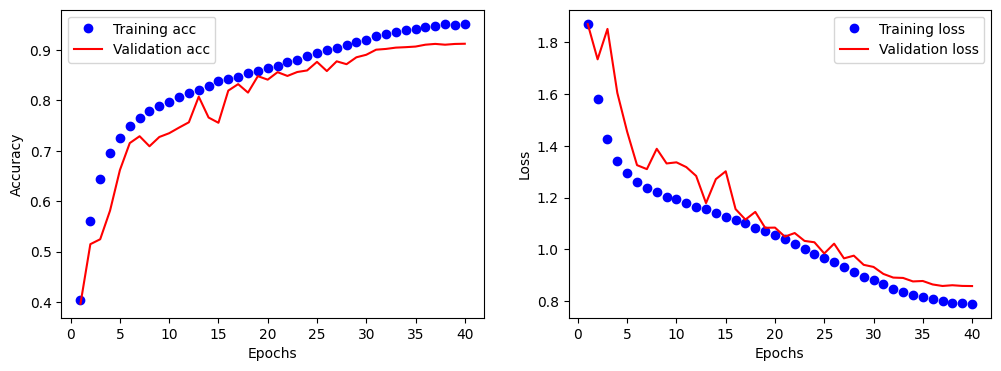

Final training accuracy   (40K, with augmentation): 0.9524
Final validation accuracy (10K): 0.9126
Best validation accuracy: 0.9126 (epoch 40)


In [10]:
import matplotlib.pyplot as plt
%matplotlib inline

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'r', label='Validation acc')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, loss, 'bo', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig(os.path.join(SAVE_DIR, 'training_curves.png'), dpi=120, bbox_inches='tight')
plt.show()

print('Final training accuracy   (40K, with augmentation): %.4f' % acc[-1])
print('Final validation accuracy (10K): %.4f' % val_acc[-1])
print('Best validation accuracy: %.4f (epoch %d)' % (max(val_acc), numpy.argmax(val_acc) + 1))

## 3. Train (again) and evaluate the model

- To this end, you have found the "best" hyper-parameters.
- Now, fix the hyper-parameters and train the network on the entire training set (all the 50K training samples)
- Evaluate your model on the test set.

### 3.1. Train the model on the entire training set

Why? Previously, you used 40K samples for training; you wasted 10K samples for the sake of hyper-parameter tuning. Now you already know the hyper-parameters, so why not using all the 50K samples for training?

We build a brand-new network (fresh weights), compile it with the same hyper-parameters, and train it on all 50K samples with the same number of epochs.

In [11]:
# keep the validation accuracy of the Section-2.4 model for the final summary
val_acc_section2 = val_acc[-1]

keras.backend.clear_session()
keras.utils.set_random_seed(0)
final_model = build_cnn()
compile_model(final_model, best_lr)   # same hyper-parameters as before

In [12]:
final_history = final_model.fit(x_train_n, y_train_vec, batch_size=BATCH_SIZE, epochs=EPOCHS,
                                callbacks=[make_lr_callback(best_lr, EPOCHS)],
                                verbose=2)   # no validation_data: there is no validation set now

final_model.save_weights(os.path.join(SAVE_DIR, 'final_model_50k.weights.h5'))
print('Saved final weights to ' + SAVE_DIR)

Epoch 1/40
391/391 - 26s - 67ms/step - accuracy: 0.4341 - loss: 1.8146 - learning_rate: 0.0010
Epoch 2/40
391/391 - 21s - 55ms/step - accuracy: 0.5957 - loss: 1.5188 - learning_rate: 0.0020
Epoch 3/40
391/391 - 21s - 54ms/step - accuracy: 0.6771 - loss: 1.3703 - learning_rate: 0.0020
Epoch 4/40
391/391 - 21s - 54ms/step - accuracy: 0.7219 - loss: 1.2997 - learning_rate: 0.0020
Epoch 5/40
391/391 - 21s - 55ms/step - accuracy: 0.7494 - loss: 1.2624 - learning_rate: 0.0020
Epoch 6/40
391/391 - 21s - 55ms/step - accuracy: 0.7672 - loss: 1.2380 - learning_rate: 0.0020
Epoch 7/40
391/391 - 21s - 55ms/step - accuracy: 0.7804 - loss: 1.2202 - learning_rate: 0.0019
Epoch 8/40
391/391 - 21s - 54ms/step - accuracy: 0.7921 - loss: 1.2066 - learning_rate: 0.0019
Epoch 9/40
391/391 - 21s - 54ms/step - accuracy: 0.8013 - loss: 1.1975 - learning_rate: 0.0019
Epoch 10/40
391/391 - 21s - 54ms/step - accuracy: 0.8099 - loss: 1.1844 - learning_rate: 0.0018
Epoch 11/40
391/391 - 21s - 54ms/step - accuracy:

### 3.2. Evaluate the model on the test set

Do NOT used the test set until now. Make sure that your model parameters and hyper-parameters are independent of the test set.

In [13]:
loss_and_acc = final_model.evaluate(x_test_n, y_test_vec)
print('loss = ' + str(loss_and_acc[0]))
print('accuracy = ' + str(loss_and_acc[1]))

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9189 - loss: 0.8393
loss = 0.8393366932868958
accuracy = 0.9189000129699707


## 4. Summary of the results

In [14]:
# training accuracy of the final model on the (un-augmented) 50K training images
train_loss_acc = final_model.evaluate(x_train_n, y_train_vec, verbose=0)

print('Training   accuracy (final model, 50K, no augmentation): %.4f' % train_loss_acc[1])
print('Validation accuracy (model of Section 2.4, 10K held-out): %.4f' % val_acc_section2)
print('Test       accuracy (final model, 10K test):              %.4f' % loss_and_acc[1])
print()
print('Hyper-parameters used: peak learning rate = %g, epochs = %d, batch size = %d, label smoothing = %g'
      % (best_lr, EPOCHS, BATCH_SIZE, LABEL_SMOOTHING))

results = {'train_accuracy': float(train_loss_acc[1]),
           'validation_accuracy': float(val_acc_section2),
           'test_accuracy': float(loss_and_acc[1]),
           'test_loss': float(loss_and_acc[0]),
           'best_lr': float(best_lr), 'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
           'label_smoothing': LABEL_SMOOTHING}
with open(os.path.join(SAVE_DIR, 'results.json'), 'w') as f:
    json.dump(results, f, indent=2)
print('Saved results to ' + os.path.join(SAVE_DIR, 'results.json'))

Training   accuracy (final model, 50K, no augmentation): 0.9744
Validation accuracy (model of Section 2.4, 10K held-out): 0.9126
Test       accuracy (final model, 10K test):              0.9189

Hyper-parameters used: peak learning rate = 0.002, epochs = 40, batch size = 128, label smoothing = 0.1
Saved results to /content/CS583_Programming2_outputs/results.json


### 4.1. Per-class accuracy and confusion matrix on the test set

Per-class test accuracy:
  airplane   0.9300
  automobile 0.9730
  bird       0.9030
  cat        0.8390
  deer       0.9310
  dog        0.8350
  frog       0.9540
  horse      0.9290
  ship       0.9520
  truck      0.9430
Hardest class: dog, easiest class: automobile
Most frequent confusions (true -> predicted : count):
  dog        -> cat        : 102
  cat        -> dog        : 51
  truck      -> automobile : 29
  ship       -> airplane   : 25
  bird       -> cat        : 24


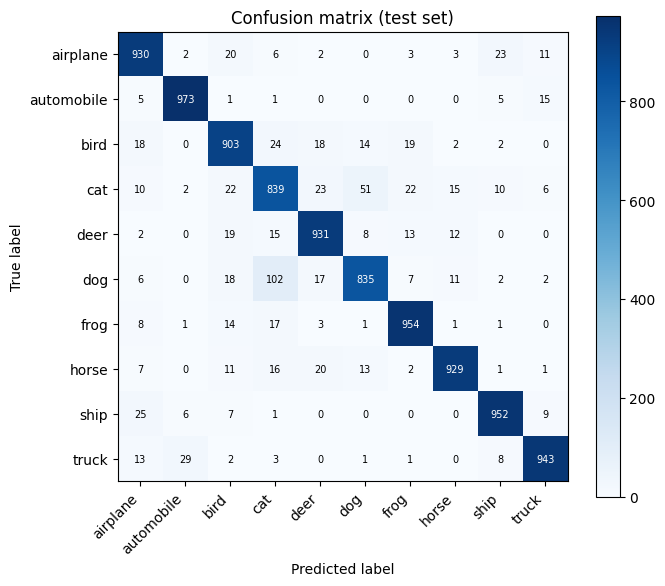

In [15]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

y_pred = numpy.argmax(final_model.predict(x_test_n, batch_size=256, verbose=0), axis=1)
y_true = numpy.asarray(y_test).reshape(-1).astype(int)

conf_mat = numpy.zeros((10, 10), dtype=int)
for t, p in zip(y_true, y_pred):
    conf_mat[t, p] += 1

per_class_acc = conf_mat.diagonal() / conf_mat.sum(axis=1)
print('Per-class test accuracy:')
for name, a in zip(class_names, per_class_acc):
    print('  %-10s %.4f' % (name, a))
print('Hardest class: %s, easiest class: %s'
      % (class_names[int(numpy.argmin(per_class_acc))], class_names[int(numpy.argmax(per_class_acc))]))

# most frequent confusions (off-diagonal)
off = conf_mat.copy()
numpy.fill_diagonal(off, 0)
top = numpy.dstack(numpy.unravel_index(numpy.argsort(off.ravel())[::-1][:5], off.shape))[0]
print('Most frequent confusions (true -> predicted : count):')
for t, p in top:
    print('  %-10s -> %-10s : %d' % (class_names[t], class_names[p], off[t, p]))

plt.figure(figsize=(7, 6))
plt.imshow(conf_mat, cmap='Blues')
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45, ha='right')
plt.yticks(range(10), class_names)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion matrix (test set)')
for i in range(10):
    for j in range(10):
        plt.text(j, i, conf_mat[i, j], ha='center', va='center', fontsize=7,
                 color='white' if conf_mat[i, j] > conf_mat.max() / 2 else 'black')
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'confusion_matrix.png'), dpi=120, bbox_inches='tight')
plt.show()

## 5. Answers to the questions

**Q2. What improvements have I made?**

1. **More layers + Dropout**: the example CNN (2 conv layers + 1 dense layer) was replaced by a VGG-style CNN with 6 conv layers (64-64-128-128-256-256 filters), global average pooling and a 256-unit dense layer (about 1.2M parameters). Dropout (0.1 / 0.2 / 0.3 in the conv stages and 0.4 in the dense head) is placed *before* the conv/dense layers it regularizes, and a small L2 weight decay (1e-4) is used.
2. **Batch normalization**: every Conv/Dense layer, including the output layer, is followed by BatchNormalization and then the activation (Conv/Dense -> BN -> ReLU/softmax), which makes training much faster and more stable and allows a much larger learning rate.
3. **Data augmentation**: random horizontal flips and random translations (up to 12.5%, reflect padding) are applied on the fly during training, which strongly reduces over-fitting.
4. **Something else**: per-channel standardization of the input (statistics computed on the training split only); Adam optimizer with a learning-rate warm-up + cosine decay (the original used RMSprop with a constant learning rate of 1e-5); label smoothing (0.1) on the cross-entropy loss; 40 epochs instead of 10; the peak learning rate was selected on the validation set (mean of the last 3 epochs, to reduce noise); mixed-precision training to make the GPU training faster; finally the network was re-trained from scratch on all 50K training samples. Per-class accuracies and a confusion matrix are reported in Section 4.1.

**Q3. What are my training, validation, and test accuracies?**

The exact numbers are printed in the output of Section 4 above. After running the notebook, fill them in here:

| | Accuracy |
|---|---|
| Training (final model, 50K, no augmentation) | **TODO** |
| Validation (Section 2.4 model, 10K held-out) | **TODO** |
| Test (final model, 10K test) | **TODO** |